# Q2E | Train Polynomial Regression

> *E. Repeat everything from part D with polynomial regression and using SGD. Using validation loss, explore if your model overfits/underfits the data and report your findings. Ensure reproducibility by using a seed.*

Part E repeats part D, so part D is quoted too:

> *D. Train a Linear Regression model using the training data with four-fold cross-validation and with appropriate evaluation metric. Do this with a closed-form solution (using the Normal Equation or SVD) and with SGD. Then focus on SGD and perform Ridge, Lasso and Elastic Net regularization: try three values of penalty term and describe its impact. Explore the impact of other hyperparameters of your choice, such as learning rate (no need for grid search). Describe your findings. Select the best-performing regularization set of hyperparameters and train that model on the entire training dataset. For SGD, display the training and validation loss as a function of training epochs for the selected model. (Hint: In scikit-learn, max_iter counts epochs (full passes over the training set). To plot training/validation loss by epoch with SGDRegressor, set max_iter=1 and warm_start=True, then call fit(...) in a loop; after each call (each epoch), compute and record Train and Validation RMSE). Ensure reproducibility by using a seed.*

---

#### IMPORTANT

This dataset has no `train` / `test` split of its own, so the same chronological split as Q2B, Q2C and Q2D is made at the top of this notebook: the earliest 584 days are `train` and the latest 147 days are `test`. Every model below is fit and scored on the training rows only, so no modeling decision is influenced by the test data (`data snooping`).

# Answer Summary

**Setup:** every model is one pipeline scored on the same 4 time-ordered folds as Q2D (each trains on the days before its validation block and validates on the next 46 days). The metric is rmse, in `Rentals` units. A model only counts as better when its rmse gain is more than 1 SE of the per-fold differences (a **candidate**), and ties go to the simpler model. With 4 folds that SE is a rough estimate. Every `random_state` is set to 42.

**Polynomial regression next to Q2D's linear model**

| Model | rmse | train rmse | Against Q2D's selected model |
|---|---|---|---|
| Dummy (always the mean) | 2521.601 | 1476.256 | worse |
| Linear, closed form | 789.225 | 569.933 | candidate |
| Linear, Lasso SGD (Q2D's selected model) | 792.708 | 570.165 | |
| Degree 2, closed form | 772.910 | 520.856 | candidate |
| Degree 2, SGD, no penalty | 766.258 | 521.987 | candidate |
| Degree 2, Lasso SGD, `alpha=0.001`, `eta0=0.001` (selected) | 767.440 | 522.146 | candidate |

train rmse is the same model scored on its own training rows. It sits well below rmse on every row, the Dummy included, because each fold validates on later days than it trains on.

- **Degree 2 polynomial regression beats the linear model, by a modest margin.** The selected model's rmse is 767.440 against 792.708, lower by 25.268 with an SE of 11.763. Closed form picks the degree: 789.225, 772.910, 766.501 and 776.078 at degrees 1 to 4. Degree 2 is the only **candidate** over the linear model, and degrees 3 and 4 are within noise of it.
- **Which columns are expanded matters more than the degree.** The polynomial terms are built from the 4 continuous feature columns only (Temp, FeelsLike's flat top, Humidity, Wind). With FeelsLike as stored the model is worse (851.334). Expanding all 10 feature columns overfits (training rmse 458.010, validation rmse 793.152) and fails on every fold at degree 3. Adding Year to the expansion has the lowest mean (725.197) but is within noise, and at degree 3 it fails on one fold.
- **SGD reaches the same fit as closed form** (769.686 against 772.910 at the default learning rate).
- **The learning rate and the stopping rule:** `eta0=0.001` is the only rate that improves on the default (766.258). 0.0001 and 0.01 are worse than it, and 0.1 ties with it but stops after 14 to 20 epochs with a training rmse of 559.602. Every fit stops by its rule, and none reaches the limit of 1,000,000 epochs. A looser tolerance stops too early: rmse is 780.515 at `tol=10` and 981.985 at `tol=1000`.
- **Regularization does not help.** Lasso at `alpha` 0.001 and 0.01 ties with plain SGD and sets no coefficient to 0. Ridge and Elastic Net are worse at every `alpha` and underfit as it grows: at 0.1 rmse is 917.411 and 895.279.
- **The selected model is Lasso at `alpha=0.001`,** the smaller of the two tied penalties. It is selected because the question asks for a regularized model, not because the penalty helps. Fit on all 584 training rows it stops after 1,753 epochs with a training rmse of 569.145.
- **Overfitting and underfitting, read from validation loss:**
  - **The selected model** does not underfit and overfits only slightly. Its validation rmse is lowest at epoch 416 (769.948) and ends at 774.678 after 10,000 epochs, with training rmse at 521.987.
  - **Degree 1 underfits.** Its two lines go flat higher up (570.834 and 790.701).
  - **Degrees 3 and 4 fit the training rows more closely, with no gain that holds.** Their training rmse keeps falling (505.481 and 483.774 at the last epoch) while their validation rmse levels off (760.799 and 760.388), within noise of degree 2.
  - **Too many columns overfit:** all 10 feature columns expanded, as above.
  - **A strong penalty or an early stop underfits:** training and validation rmse rise together.

**Carried forward:** the fitted pipeline, saved as `polynomial_regression.joblib`. It takes the 11 attributes as they are stored, and its cross validated rmse of 767.440 is the estimate for days it has not seen.

---

# Imports

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor

from Q2.consts import *

from utils import (
	read_csv_to_df,
	PLOTTING,
	SCORING,
	FEATURES,
	PIPELINES,
)

from Q2.utils import (
	chronological_split,
	make_time_folds,
	Q2_FEATURES,
)

# Fetch Data

In [2]:
df = read_csv_to_df(path=DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=SHORT_NAMES)

# Train / Test Split

In [3]:
train_df, test_df = chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


`test_df` is not used again in this notebook.

# Setup

## Attributes

In [4]:
CONTINUOUS = ["Temp", "FeelsLike", "Humidity", "Wind"]
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]

# the same 11 attributes as Q2D. ID, Date, Casual and Registered are left out, as concluded in Q2B
ATTRIBUTES = CONTINUOUS + BINARY + MULTI_LEVEL

X = train_df[ATTRIBUTES]
y = train_df[TARGET]

print(f"rows: {len(X)} | attributes: {len(ATTRIBUTES)} | missing values: {int(X.isna().sum().sum())}")

rows: 584 | attributes: 11 | missing values: 0


## Folds

In [5]:
FOLDS = make_time_folds(train_df, date_col="Date", n_splits=CV_SPLITS, validation_size=CV_TEST_SIZE)

fold_rows = []
for train_labels, validation_labels in FOLDS.folds:
	train_rows, validation_rows = train_df.loc[train_labels], train_df.loc[validation_labels]
	fold_rows.append({
		"train rows": len(train_rows),
		"train rows in Year 1": int((train_rows["Year"] == 1).sum()),
		"validation rows": len(validation_rows),
		"validation first date": f"{validation_rows['Date'].min():%Y-%m-%d}",
		"validation last date": f"{validation_rows['Date'].max():%Y-%m-%d}",
	})

pd.DataFrame(fold_rows, index=pd.RangeIndex(1, len(FOLDS) + 1, name="fold"))

,train rows,train rows in Year 1,validation rows,validation first date,validation last date
fold,,,,,
1,400,35,46,2012-02-05,2012-03-21
2,446,81,46,2012-03-22,2012-05-06
3,492,127,46,2012-05-07,2012-06-21
4,538,173,46,2012-06-22,2012-08-06


## Feature Columns

In [6]:
# the two shapes Q2D selected
#   LowHinge: [max(0, t - x)], a flat top: 0 at or above t, growing as x falls below it
#   Cyclical: [sin(2π·x / 12), cos(2π·x / 12)]
SHAPES = {
	"FeelsLike": {"shape": FEATURES.LowHinge(t=0.60)},
	"Month": {"sine / cosine": Q2_FEATURES.Cyclical(period=12)},
}

# Q2D's selected feature set: 10 feature columns from 9 of the 11 attributes
Q2D_FEATURES = {"FeelsLike": "shape", "Month": "sine / cosine", "IsWorkday": "drop", "IsHoliday": "drop"}


def build(choice, estimator, *, degree=1, expand=CONTINUOUS, scale=False):
	"""One pipeline for a feature choice, a degree and a model: features > (polynomial terms) > (scaler) > model.

	Args:
		choice: What each attribute contributes: "raw", "drop" or the name of one of its SHAPES. Attributes left
			out are "raw", so {} is the 11 attributes as they are stored.
		estimator: Final model.
		degree: Degree of the polynomial terms. 1 adds nothing.
		expand: Attributes whose feature columns the polynomial terms are built from. The other feature columns
			go to the model as they are. None builds the terms from every feature column.
		scale: Standardize the columns before the model and, with degree above 1, also before the polynomial
			terms are built.
	"""
	return PIPELINES.attribute_pipeline(
		estimator, attributes=ATTRIBUTES, shapes=SHAPES, choice=choice, degree=degree, expand=expand, scale=scale,
	)


def column_counts(settings):
	"""Columns each setting gives the model, and how many of them are independent.

	Args:
		settings: {row label: build arguments}, ex {"Degree 2": {"choice": Q2D_FEATURES, "degree": 2}}.

	Returns:
		One row per setting: "columns", and "independent", the rank of the standardized columns on all the
		training rows. A lower number than "columns" means some columns are exact combinations of others.
	"""
	rows = {}
	for name, arguments in settings.items():
		columns = build(estimator=LinearRegression(), scale=True, **arguments)[:-1].fit_transform(X)
		rows[name] = {"columns": columns.shape[1], "independent": np.linalg.matrix_rank(columns)}
	return pd.DataFrame.from_dict(rows, orient="index")


feature_columns = build(Q2D_FEATURES, LinearRegression())["features"].fit(X).get_feature_names_out()
display(pd.Series(feature_columns, index=pd.RangeIndex(1, len(feature_columns) + 1), name="Q2D's feature columns").to_frame())

# what degree 2 adds: each continuous feature column squared and each pair of them multiplied
degree_2_columns = build(Q2D_FEATURES, LinearRegression(), degree=2)["features"].fit(X).get_feature_names_out()
print("added at degree 2:", ", ".join(column for column in degree_2_columns if column not in feature_columns))

# the columns each degree gives the model, with the 4 continuous feature columns expanded
display(column_counts({f"Degree {degree}": {"choice": Q2D_FEATURES, "degree": degree} for degree in [1, 2, 3, 4]}))

,Q2D's feature columns
1,Temp
2,FeelsLike__low_hinge_0.6
3,Humidity
4,Wind
5,Year
6,Season
7,Month__sin
8,Month__cos
9,Weekday
10,Weather


added at degree 2: Temp^2, Temp FeelsLike__low_hinge_0.6, Temp Humidity, Temp Wind, FeelsLike__low_hinge_0.6^2, FeelsLike__low_hinge_0.6 Humidity, FeelsLike__low_hinge_0.6 Wind, Humidity^2, Humidity Wind, Wind^2


,columns,independent
Degree 1,10,10
Degree 2,20,20
Degree 3,40,40
Degree 4,75,75


## Scoring

In [7]:
RESULTS = {}


def score(name, pipeline):
	"""Score a pipeline on FOLDS and keep its per-fold scores in RESULTS under name.

	Args:
		name: Row label of the model in every table.
		pipeline: Model or pipeline to score.
	"""
	RESULTS[name] = PIPELINES.evaluate_pipeline(pipeline, X=X, y=y, folds=FOLDS, return_train_score=True)


def table(names, *, baseline, holm=False):
	"""Results table of the named models, with the noise threshold against baseline.

	Args:
		names: Models to show, each already scored with score.
		baseline: Name of the model the rmse difference is measured against. It must be in names.
		holm: Add the Holm adjusted p and the "significant" verdict.
	"""
	return SCORING.results_df({name: RESULTS[name] for name in names}, baseline=baseline, holm=holm)


def fold_range(names):
	"""The spread of the named models over the folds, for a model that fails on some of them.

	Args:
		names: Models to show, each already scored with score. "Dummy" must be scored too.

	Returns:
		One row per model: its mean validation and training rmse, its lowest, median and highest fold rmse, and
		the number of folds where its rmse is above the Dummy's on the same fold. The rmse columns are text, so
		a run in the billions does not push the whole table into scientific notation.
	"""
	rows = {}
	for name in names:
		rmse = RESULTS[name]["rmse"]
		values = {
			"rmse mean": rmse.mean(),
			"train rmse mean": RESULTS[name]["train_rmse"].mean(),
			"lowest fold": rmse.min(),
			"median fold": np.median(rmse),
			"highest fold": rmse.max(),
		}
		rows[name] = {column: f"{value:.3f}" if value < 1e6 else f"{value:.2e}" for column, value in values.items()}
		rows[name]["folds above Dummy"] = int((rmse > RESULTS["Dummy"]["rmse"]).sum())
	return pd.DataFrame.from_dict(rows, orient="index")

# Method

Every model is one `Pipeline` from `build(choice, estimator, degree=, expand=)`: features, (polynomial terms), (scaler), model. `choice` sets each attribute to `"raw"`, `"drop"` or the name of one of its shapes in `SHAPES`, and every step is fit inside each training fold.

- **Polynomial regression:** linear regression on extra columns. At degree 2 the pipeline adds each expanded column squared and each pair of expanded columns multiplied, at degree 3 every product of three, and at degree 4 every product of four. Degree 1 adds nothing.
- **What is expanded:** the starting point is Q2D's selected feature columns (`Q2D_FEATURES`), with the polynomial terms built from the 4 continuous ones (Temp, FeelsLike's flat top, Humidity, Wind). The other 6 columns (Year, Season, Month's sine and cosine, Weekday, Weather) go to the model as they are, because they are a 0 / 1 flag and calendar or category codes, not quantities. So the degree 1 model is Q2D's model, and a higher degree changes only the polynomial terms. What Is Expanded tests that choice. FeelsLike's threshold is Q2D's, found on all the training rows, so its gain is slightly optimistic.
- **Rows:** no attribute has a missing value, so every model uses all 584 training rows.
- **Folds:** the same 4 time-ordered folds as Q2D, built once and used by every model, so a polynomial model can be compared with Q2D's models fold by fold. Each fold trains on every day before its validation block and validates on the next 46 days.
- **Limit:** 4 folds give 4 differences per comparison, so the SE below is a rough estimate and **significant** is hard to reach.
- **Metric:** rmse. It is in `Rentals` units, counts large misses more than small ones, and is the squared error a linear regression minimizes. mae and r2 are reported next to it, and `train rmse mean` is the same model scored on its own training rows.
- **Scaling:** SGD models standardize the feature columns before the polynomial terms are built, and standardize every column again before the model. Closed form uses no scaler. `Rentals` stays in its own units.
- **SGD stopping:** SGD models use scikit-learn's default tolerance with `max_iter=1_000_000`, as in Q2D, so a run stops by its rule and not at the epoch limit. The two rows in Stopping Tolerance are the exception: they show what a looser tolerance does.
- **Redundant columns:** a polynomial column can be an exact combination of others (ex a 0 / 1 column squared is the column itself). It does not change a prediction, but it leaves closed form more than one set of coefficients that fits equally well. `column_counts` counts them: `independent` is lower than `columns`.
- **Seed:** the folds are not shuffled, so they need no seed. Every `random_state` in a pipeline is set to 42 before it is fit, so a rerun gives the same numbers.

**Noise threshold (Δrmse vs the baseline)**

- Δ is the mean of the per-fold rmse differences d (model minus baseline). Negative means lower error than the baseline.
- The folds share most of their training rows, so the SE of Δ uses the Nadeau and Bengio correction: `SE = sqrt(var(d) · (1/folds + n_test/n_train))`. `Δ / SE` is the corrected t statistic and `p` its one-sided p-value.
- `verdict`:
  - **within noise:** Δ is within 1 SE of 0.
  - **candidate:** Δ is below -1 SE.
  - **worse:** Δ is above +1 SE.
  - **significant** (tables with `p (Holm)` only): the Holm adjusted p is below 0.05, adjusted over that table's rows.
- **A model that fails on some folds** (an rmse above the Dummy's on that fold) gets no verdict. Those folds set both its mean and its SE, so `fold_range` shows its lowest, median and highest fold in their place.

**Decisions**

- **Ties go to the simpler model.** A row that adds something (columns, a penalty) is kept only if it is **candidate** or **significant**. A row that removes something is kept unless it is **worse**.
- **Among tied settings the smaller one wins:** the smaller penalty, as the model closest to no penalty, and the smaller learning rate.
- **The degree is chosen with closed form,** which fits each degree to the end, so the choice does not depend on where SGD stops.
- **Each section's choice is the next section's baseline.**

# Baselines

A model that always predicts the mean `Rentals`, then Q2D's two models scored again on the same folds. They are the rows every polynomial model is compared with.

## Dummy Regressor

In [8]:
score("Dummy", DummyRegressor(strategy="mean"))
display(table(["Dummy"], baseline="Dummy"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Dummy,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Dummy,2521.601,670.512,1476.256,2317.678,765.003,-5.379,4.344,0.0,NaN,NaN,NaN,baseline,4


## Q2D's Linear Models

Both are degree 1 on `Q2D_FEATURES`: closed form `LinearRegression`, and Q2D's selected model, Lasso SGD at `alpha=0.001` and `eta0=0.0001`.

In [9]:
# the epoch limit Q2D gave its SGD models, kept for every SGD model in this notebook
MAX_ITER = 1_000_000

score("Linear, closed form", build(Q2D_FEATURES, LinearRegression()))
score("Linear, Lasso SGD", build(Q2D_FEATURES, SGDRegressor(penalty="l1", alpha=0.001, eta0=0.0001, max_iter=MAX_ITER), scale=True))

display(table(["Dummy", "Linear, closed form", "Linear, Lasso SGD"], baseline="Linear, closed form"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Linear, closed form",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Linear, closed form",789.225,76.185,569.933,597.399,68.178,0.465,0.160,0.000,NaN,NaN,NaN,baseline,4
"Linear, Lasso SGD",792.708,78.107,570.165,602.409,71.633,0.461,0.160,3.483,1.136,3.066,0.973,worse,4
Dummy,2521.601,670.512,1476.256,2317.678,765.003,-5.379,4.344,1732.376,392.296,4.416,0.989,worse,4


## Results

- **Q2D's two models score here what they scored in Q2D.** `Linear, closed form` has an rmse of 789.225 and `Linear, Lasso SGD` 792.708, so the folds and the pipeline are the same. The SGD model is slightly worse: 3.483 higher, against an SE of 1.136.
- **Both are far below the Dummy** (2521.601), which has a negative r2 (-5.379) against 0.465 and 0.461.
- **Training rmse is well below validation rmse on every row, the Dummy included** (1476.256 against 2521.601). The Dummy has no columns to overfit with, so that gap comes from the folds, where each validation block holds later days than its training rows. For the linear models it is 569.933 against 789.225, and a polynomial model's gap is read against that one.

**Carry forward**

- **`Linear, closed form`** (rmse 789.225) as the degree 1 model the Degree section starts from.
- **`Linear, Lasso SGD`** (rmse 792.708), Q2D's selected model, as the row the selected polynomial model is compared with.

# Polynomial Features

Which degree, and which columns are expanded. Every model in this section is closed form `LinearRegression`, which has no learning rate or seed to add noise to the comparison.

## Degree

The 4 continuous feature columns expanded to degrees 2, 3 and 4. Degree 1 is `Linear, closed form`, the same columns with no polynomial terms.

In [10]:
DEGREES = {f"Degree {degree}": degree for degree in [2, 3, 4]}

for name, degree in DEGREES.items():
	score(name, build(Q2D_FEATURES, LinearRegression(), degree=degree))

# every degree over the folds: a degree with a fold above the Dummy's rmse gets no verdict below
display(fold_range(["Linear, closed form", *DEGREES]))

,rmse mean,train rmse mean,lowest fold,median fold,highest fold,folds above Dummy
"Linear, closed form",789.225,569.933,703.071,784.345,885.139,0
Degree 2,772.910,520.856,660.331,769.278,892.753,0
Degree 3,766.501,500.501,641.446,781.936,860.688,0
Degree 4,776.078,474.315,604.865,810.714,878.018,0


In [11]:
display(table(["Linear, closed form", *DEGREES], baseline="Linear, closed form"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Linear, closed form",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Degree 3,766.501,104.750,500.501,599.383,83.270,0.500,0.134,-22.724,26.783,-0.848,0.229,within noise,4
Degree 2,772.910,97.834,520.856,602.901,91.959,0.492,0.135,-16.315,13.008,-1.254,0.149,candidate,4
Degree 4,776.078,129.791,474.315,608.352,102.229,0.496,0.118,-13.147,41.178,-0.319,0.385,within noise,4
"Linear, closed form",789.225,76.185,569.933,597.399,68.178,0.465,0.160,0.000,NaN,NaN,NaN,baseline,4


The same degrees against degree 2, the lowest degree that is a **candidate** above:

In [12]:
display(table(list(DEGREES), baseline="Degree 2"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Degree 2,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Degree 3,766.501,104.750,500.501,599.383,83.270,0.500,0.134,-6.409,21.267,-0.301,0.391,within noise,4
Degree 2,772.910,97.834,520.856,602.901,91.959,0.492,0.135,0.000,NaN,NaN,NaN,baseline,4
Degree 4,776.078,129.791,474.315,608.352,102.229,0.496,0.118,3.167,32.918,0.096,0.535,within noise,4


### Results

- **Degree 2 is better than the linear model, by a small margin.** rmse falls from 789.225 to 772.910, a change of -16.315 against an SE of 13.008 (Δ / SE -1.254). It is the only degree that is a **candidate**.
- **Degrees 3 and 4 add nothing that holds.** Against degree 2 they are within noise: -6.409 (SE 21.267) and 3.167 (SE 32.918). Degree 3 has the lowest mean (766.501), but its gain over the linear model changes more from fold to fold (SE 26.783 against 13.008), so the tie goes to the lower degree.
- **From degree 2 on, the extra columns fit the training rows more closely without predicting later days better.** Training rmse keeps falling (520.856, 500.501 and 474.315 at degrees 2, 3 and 4) while validation rmse stays where it is (772.910, 766.501 and 776.078). At degree 4 the median fold (810.714) is above the linear model's (784.345).
- **No degree fails.** None has a fold above the Dummy's rmse, so every row has a verdict.

**Carry forward**

- **`Degree 2`** (rmse 772.910) as the baseline for What Is Expanded.

**Ignore**

- **Degrees 3 and 4,** as closed form models. The Overfitting and Underfitting section looks at them again with SGD.

## What Is Expanded

Whether the degree 2 terms should be built from Q2D's 4 continuous feature columns, or from a different set.

### Alternatives at Degree 2

Each row changes one thing in `Degree 2`:

- **FeelsLike as stored:** its flat top taken back out, so the polynomial terms have to make the bend.
- **11 attributes as stored:** no shapes and no drops, with the 4 continuous attributes expanded.
- **IsWorkday + IsHoliday put back:** Q2D's two drops undone. Neither is expanded.
- **Year also expanded:** Year joins the 4 continuous columns, which adds its product with each of them.
- **All 10 columns expanded:** every feature column, the codes included.

In [13]:
# each alternative as the build arguments it changes
ALTERNATIVES = {
	"FeelsLike as stored": {"choice": {**Q2D_FEATURES, "FeelsLike": "raw"}},
	"11 attributes as stored": {"choice": {}},
	"IsWorkday + IsHoliday put back": {"choice": {attribute: pick for attribute, pick in Q2D_FEATURES.items() if pick != "drop"}},
	"Year also expanded": {"choice": Q2D_FEATURES, "expand": CONTINUOUS + ["Year"]},
	"All 10 columns expanded": {"choice": Q2D_FEATURES, "expand": None},
}

for name, arguments in ALTERNATIVES.items():
	score(name, build(estimator=LinearRegression(), degree=2, **arguments))

# the columns each one gives the model at degree 2
display(column_counts({
	"Degree 2": {"choice": Q2D_FEATURES, "degree": 2},
	**{name: {**arguments, "degree": 2} for name, arguments in ALTERNATIVES.items()},
}))
display(table(["Degree 2", *ALTERNATIVES], baseline="Degree 2"))

,columns,independent
Degree 2,20,20
FeelsLike as stored,20,20
11 attributes as stored,21,21
IsWorkday + IsHoliday put back,22,22
Year also expanded,25,24
All 10 columns expanded,65,63


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs Degree 2,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
Year also expanded,725.197,119.665,503.900,531.414,107.073,0.528,0.205,-47.713,50.008,-0.954,0.205,within noise,4
Degree 2,772.910,97.834,520.856,602.901,91.959,0.492,0.135,0.000,NaN,NaN,NaN,baseline,4
IsWorkday + IsHoliday put back,775.032,97.010,516.655,601.613,97.432,0.487,0.143,2.122,3.352,0.633,0.714,within noise,4
All 10 columns expanded,793.152,98.382,458.010,635.883,75.704,0.447,0.225,20.242,40.443,0.501,0.674,within noise,4
FeelsLike as stored,851.334,132.609,572.089,684.626,139.891,0.388,0.154,78.424,20.560,3.814,0.984,worse,4
11 attributes as stored,917.334,193.989,592.691,763.513,219.955,0.280,0.245,144.424,60.131,2.402,0.952,worse,4


### The Larger Expansions at Degree 3

The two alternatives that expand more columns, one degree up, next to `Degree 3`.

In [14]:
LARGER = {f"{name}, degree 3": ALTERNATIVES[name] for name in ["Year also expanded", "All 10 columns expanded"]}

for name, arguments in LARGER.items():
	score(name, build(estimator=LinearRegression(), degree=3, **arguments))

display(column_counts({name: {**arguments, "degree": 3} for name, arguments in LARGER.items()}))
display(fold_range(["Degree 3", *LARGER]))

,columns,independent
"Year also expanded, degree 3",60,54
"All 10 columns expanded, degree 3",285,262


,rmse mean,train rmse mean,lowest fold,median fold,highest fold,folds above Dummy
Degree 3,766.501,500.501,641.446,781.936,860.688,0
"Year also expanded, degree 3",1588.663,476.753,650.296,970.515,3763.328,1
"All 10 columns expanded, degree 3",31787.778,290.568,3151.706,27818.024,68363.358,4


### Results

- **FeelsLike's flat top still earns its place.** With FeelsLike as stored, rmse is 851.334, worse than `Degree 2` by 78.424 against an SE of 20.560, so the polynomial terms do not replace the flat top. The 11 attributes as stored score 917.334, also worse.
- **Year in the expansion has the lowest mean, but the gain does not hold.** Its rmse is 725.197, a change of -47.713 against an SE of 50.008, which is within noise, so it is not added. One degree up it is above the Dummy on one fold (3763.328).
- **Expanding all 10 columns overfits.** At degree 2 its 65 columns bring training rmse down to 458.010 while validation rmse goes up to 793.152 (within noise). At degree 3 its 285 columns bring training rmse to 290.568, and it is above the Dummy on all 4 folds.
- **IsWorkday and IsHoliday stay out.** Putting them back scores 775.032, within noise (2.122 against an SE of 3.352).

**Carry forward**

- **`Degree 2`** (rmse 772.910) as it is: polynomial terms from Temp, FeelsLike's flat top, Humidity and Wind, with the other 6 columns unexpanded. That is 20 columns, all independent.

**Ignore**

- **The five alternatives.** Two are worse, and three add columns without a gain that holds.

# SGD

The same feature set and degree fit by stochastic gradient descent: compared with closed form, then the learning rate and the stopping tolerance.

In [15]:
# the feature set left standing in What Is Expanded, and the degree carried forward from Degree
FEATURE_CHOICE = Q2D_FEATURES
DEGREE = 2

# the closed form model on that feature set, under the name used from here on (nothing is scored again)
RESULTS["Closed form, degree 2"] = RESULTS["Degree 2"]


def sgd(**params):
	"""SGDRegressor with this notebook's epoch limit, and no penalty unless one is passed.

	Args:
		params: SGDRegressor parameters that differ from that (ex eta0, penalty, alpha, tol).
	"""
	return SGDRegressor(**{"penalty": None, "max_iter": MAX_ITER, **params})


def epochs_run(estimators, *, degree=DEGREE):
	"""Epochs each SGD model runs before it stops, on FEATURE_CHOICE at degree.

	Args:
		estimators: {row label: SGD model}.
		degree: Degree of the polynomial terms.

	Returns:
		One row per model: the epochs run on each fold's training rows and on all the training rows, and
		"fits at the limit", the number of those fits that ran all MAX_ITER epochs without stopping by tol.
	"""
	rows = {}
	for name, estimator in estimators.items():
		pipeline = build(FEATURE_CHOICE, estimator, degree=degree, scale=True)
		fold_fits = PIPELINES.evaluate_pipeline(pipeline, X=X, y=y, folds=FOLDS, return_estimator=True)["estimator"]
		rows[name] = {f"fold {fold}": fitted["model"].n_iter_ for fold, fitted in enumerate(fold_fits, start=1)}
		rows[name]["all rows"] = PIPELINES.seed_pipeline(pipeline).fit(X, y)["model"].n_iter_
	epochs = pd.DataFrame.from_dict(rows, orient="index")
	return epochs.assign(**{"fits at the limit": (epochs == MAX_ITER).sum(axis=1)})

## SGD vs Closed Form

`SGDRegressor` with no penalty and scikit-learn's default learning rate (`eta0=0.01`). It reaches its coefficients through repeated small steps, where closed form solves for them directly.

In [16]:
score("SGD", build(FEATURE_CHOICE, sgd(), degree=DEGREE, scale=True))

display(epochs_run({"SGD": sgd()}))
display(table(["Closed form, degree 2", "SGD"], baseline="Closed form, degree 2"))

,fold 1,fold 2,fold 3,fold 4,all rows,fits at the limit
SGD,107,67,51,60,51,0


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, degree 2",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
SGD,769.686,100.809,522.796,603.528,92.947,0.497,0.130,-3.224,3.736,-0.863,0.226,within noise,4
"Closed form, degree 2",772.910,97.834,520.856,602.901,91.959,0.492,0.135,0.000,NaN,NaN,NaN,baseline,4


### Results

- **SGD reaches the same fit as closed form.** Its rmse is 769.686 against 772.910, a change of -3.224 against an SE of 3.736, and its training rmse is 522.796 against 520.856.
- **It stops by its own rule, after few epochs.** The fits run 51 to 107 epochs, and none reaches the limit.

**Carry forward**

- **`SGD`** (rmse 769.686) as the baseline for the learning rate. Closed form stays the simpler model with the same score.

## Learning Rate

`eta0` is the initial learning rate, the size of the first steps. Each row changes only `eta0`. `SGD` already uses 0.01, so it is the baseline and the 0.01 row.

In [17]:
ETA0S = {f"SGD, eta0={eta0}": eta0 for eta0 in LEARNING_RATES if eta0 != 0.01}

for name, eta0 in ETA0S.items():
	score(name, build(FEATURE_CHOICE, sgd(eta0=eta0), degree=DEGREE, scale=True))

# no rate has a fold above the Dummy's rmse, so every row gets a verdict
assert not any((RESULTS[name]["rmse"] > RESULTS["Dummy"]["rmse"]).any() for name in ETA0S)

display(table(["SGD", *ETA0S], baseline="SGD"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,Δrmse vs SGD,Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.1",762.505,105.904,559.602,592.807,99.303,0.504,0.143,-7.181,14.352,-0.500,0.326,within noise,4
"SGD, eta0=0.001",766.258,98.101,521.987,600.228,91.436,0.501,0.131,-3.427,2.183,-1.570,0.107,candidate,4
"SGD, eta0=0.0001",769.108,97.555,521.546,602.179,92.086,0.497,0.135,-0.577,3.555,-0.162,0.441,within noise,4
SGD,769.686,100.809,522.796,603.528,92.947,0.497,0.130,0.000,NaN,NaN,NaN,baseline,4


The same rows against the one that is a **candidate** above, so the choice between the rates has its own verdict. Then the epochs each rate runs before it stops.

In [18]:
display(table(["SGD", *ETA0S], baseline="SGD, eta0=0.001"))

display(epochs_run({f"eta0={eta0}": sgd(eta0=eta0) for eta0 in LEARNING_RATES}))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs SGD, eta0=0.001",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.1",762.505,105.904,559.602,592.807,99.303,0.504,0.143,-3.753,15.710,-0.239,0.413,within noise,4
"SGD, eta0=0.001",766.258,98.101,521.987,600.228,91.436,0.501,0.131,0.000,NaN,NaN,NaN,baseline,4
"SGD, eta0=0.0001",769.108,97.555,521.546,602.179,92.086,0.497,0.135,2.850,1.727,1.650,0.901,worse,4
SGD,769.686,100.809,522.796,603.528,92.947,0.497,0.130,3.427,2.183,1.570,0.893,worse,4


,fold 1,fold 2,fold 3,fold 4,all rows,fits at the limit
eta0=0.0001,199893,172533,143611,68885,64824,0
eta0=0.001,4558,2826,1931,1685,1753,0
eta0=0.01,107,67,51,60,51,0
eta0=0.1,14,16,15,18,20,0


### Results

- **0.001 is the only rate that improves on the default.** It scores 766.258 against 769.686, a change of -3.427 against an SE of 2.183. Measured against it, 0.0001 is worse (2.850 against an SE of 1.727) and so is the default 0.01.
- **0.1 ties with 0.001, but it stops before it has fit the training rows.** Its rmse is 762.505, within noise of 0.001 (-3.753 against an SE of 15.710). It runs only 14 to 20 epochs, and its training rmse is 559.602 against 521.987.
- **No ranking here comes from a run that was cut off.** Every fit stops by its rule and none reaches the limit. 0.0001 runs 68,885 to 199,893 epochs on the folds against 1,685 to 4,558 for 0.001, and reaches about the same training rmse (521.546 against 521.987).

**Carry forward**

- **`eta0=0.001`** (rmse 766.258). Of the two tied rates it is the smaller one, and the one that fits the training rows.

**Ignore**

- **0.0001, 0.01 and 0.1.**

## Stopping Tolerance

SGD stops when its training loss has not improved by more than `tol` for 5 epochs in a row. The loss is a squared error, so it is in squared `Rentals`, and scikit-learn's default `tol=0.001` is a strict rule on that scale. Two looser values, at `eta0=0.001`, show what stopping earlier does.

In [19]:
LOOSER_TOL = {f"eta0=0.001, tol={tol}": sgd(eta0=0.001, tol=tol) for tol in [10, 1000]}

for name, estimator in LOOSER_TOL.items():
	score(name, build(FEATURE_CHOICE, estimator, degree=DEGREE, scale=True))

display(table(["SGD, eta0=0.001", *LOOSER_TOL], baseline="SGD, eta0=0.001"))
display(epochs_run(LOOSER_TOL))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs SGD, eta0=0.001",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.001",766.258,98.101,521.987,600.228,91.436,0.501,0.131,0.000,NaN,NaN,NaN,baseline,4
"eta0=0.001, tol=10",780.515,114.408,527.803,613.677,103.895,0.489,0.112,14.257,13.274,1.074,0.819,worse,4
"eta0=0.001, tol=1000",981.985,215.071,593.278,820.386,214.718,0.202,0.215,215.727,72.124,2.991,0.971,worse,4


,fold 1,fold 2,fold 3,fold 4,all rows,fits at the limit
"eta0=0.001, tol=10",638,622,581,564,581,0
"eta0=0.001, tol=1000",82,77,75,72,69,0


### Results

- **A looser tolerance stops SGD early, and the model underfits.** At `tol=10` the fits run 564 to 638 epochs and rmse is 780.515, worse by 14.257 against an SE of 13.274. At `tol=1000` they run 69 to 82 epochs, and training and validation rmse are both high (593.278 and 981.985).
- **The default tolerance is strict enough here.** With it the same model runs 1,685 to 4,558 epochs, reaches a training rmse of 521.987 and never comes near the epoch limit.

**Carry forward**

- **The default tolerance** for every SGD model below, and **`SGD, eta0=0.001`** (rmse 766.258) as the baseline for the penalties.

# Regularization

A penalty adds the size of the coefficients to the loss, which pulls them toward 0. `alpha` sets its strength.

- **Ridge** (`l2`): the sum of the squared coefficients.
- **Lasso** (`l1`): the sum of their absolute values, which can set a coefficient to exactly 0.
- **Elastic Net:** a mix of the two, at scikit-learn's default `l1_ratio=0.15`.

Each row changes only the penalty and its `alpha`, at the three values in `ALPHAS`. The baseline is `SGD, eta0=0.001`, the same model with no penalty.

In [20]:
# the learning rate carried forward from the SGD section
ETA0 = 0.001

PENALTIES = {"Ridge": "l2", "Lasso": "l1", "Elastic Net": "elasticnet"}

PENALIZED = {
	f"{name}, alpha={alpha}": sgd(penalty=penalty, alpha=alpha, eta0=ETA0)
	for name, penalty in PENALTIES.items()
	for alpha in ALPHAS
}

for name, estimator in PENALIZED.items():
	score(name, build(FEATURE_CHOICE, estimator, degree=DEGREE, scale=True))

display(table(["SGD, eta0=0.001", *PENALIZED], baseline="SGD, eta0=0.001", holm=True))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs SGD, eta0=0.001",Δrmse SE,Δ / SE,p,p (Holm),verdict,folds
intervention,,,,,,,,,,,,,,
"SGD, eta0=0.001",766.258,98.101,521.987,600.228,91.436,0.501,0.131,0.000,NaN,NaN,NaN,NaN,baseline,4
"Lasso, alpha=0.1",767.033,98.080,522.086,600.595,91.463,0.500,0.130,0.774,0.770,1.005,0.806,1.0,worse,4
"Lasso, alpha=0.001",767.440,97.661,522.146,600.826,91.041,0.500,0.129,1.181,1.395,0.847,0.770,1.0,within noise,4
"Lasso, alpha=0.01",767.569,97.638,522.161,600.905,91.014,0.500,0.129,1.310,1.538,0.852,0.772,1.0,within noise,4
"Elastic Net, alpha=0.001",768.092,98.432,521.986,601.896,92.187,0.499,0.131,1.833,0.494,3.714,0.983,1.0,worse,4
"Ridge, alpha=0.001",768.287,98.599,521.994,602.122,92.325,0.499,0.131,2.028,0.596,3.400,0.979,1.0,worse,4
"Elastic Net, alpha=0.01",778.569,107.461,523.832,614.653,99.637,0.488,0.124,12.311,7.236,1.701,0.906,1.0,worse,4
"Ridge, alpha=0.01",780.993,109.644,524.328,617.621,102.089,0.485,0.124,14.735,8.484,1.737,0.910,1.0,worse,4
"Elastic Net, alpha=0.1",895.279,164.119,556.219,735.888,161.551,0.331,0.163,129.021,40.511,3.185,0.975,1.0,worse,4


## Coefficients

Each setting fit once on all the training rows. The model has 20 coefficients, on standardized columns, so the table summarizes them: how many are exactly 0, the sum of their absolute values and the largest one.

In [21]:
coefficient_summary = {}
for name, estimator in {"SGD, eta0=0.001": sgd(eta0=ETA0), **PENALIZED}.items():
	fitted = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, estimator, degree=DEGREE, scale=True)).fit(X, y)
	size = np.abs(fitted["model"].coef_)
	coefficient_summary[name] = {
		"epochs run": fitted["model"].n_iter_,
		"coefficients at 0": int((size == 0).sum()),
		"sum of |coefficients|": size.sum(),
		"largest |coefficient|": size.max(),
	}

coefficient_summary = pd.DataFrame.from_dict(coefficient_summary, orient="index").round(1)
display(coefficient_summary.astype({"epochs run": int, "coefficients at 0": int}))

,epochs run,coefficients at 0,sum of |coefficients|,largest |coefficient|
"SGD, eta0=0.001",1753,0,5550.1,922.8
"Ridge, alpha=0.001",1725,0,5518.4,921.7
"Ridge, alpha=0.01",1272,0,5229.2,912.5
"Ridge, alpha=0.1",503,0,4128.0,824.5
"Lasso, alpha=0.001",1753,0,5549.9,922.8
"Lasso, alpha=0.01",1753,0,5548.2,922.8
"Lasso, alpha=0.1",1753,0,5530.9,922.7
"Elastic Net, alpha=0.001",1725,0,5522.7,921.9
"Elastic Net, alpha=0.01",1272,0,5263.4,914.1
"Elastic Net, alpha=0.1",503,0,4227.9,837.9


## Results

- **No penalty improves on plain SGD.** No setting is a **candidate**, every rmse is above 766.258, and the Holm adjusted p is 1.0 on every row.
- **Lasso barely acts at these `alpha` values.** Its three settings score 767.033 to 767.569, run the same 1,753 epochs as plain SGD and set no coefficient to 0. The sum of the absolute coefficients hardly moves (5530.9 at `alpha=0.1` against 5550.1). The coefficients are in `Rentals` units, with the largest at 922.8, so a penalty of this strength on their absolute values is small.
- **Lasso at 0.001 and 0.01 tie with plain SGD, and Lasso at 0.1 does not.** Its difference is the smallest of the three (0.774), but it changes the least from fold to fold (SE 0.770), which puts it just past 1 SE.
- **Ridge and Elastic Net underfit as `alpha` grows.** At 0.1 rmse is 917.411 and 895.279, training rmse rises with it (562.893 and 556.219 against 521.987), the sum of the absolute coefficients falls to 4128.0 and 4227.9, and the fit stops after 503 epochs. Both are already worse at 0.001 (768.287 and 768.092).

**Carry forward**

- **The two settings that tie with plain SGD:** Lasso at `alpha` 0.001 and 0.01. The selected model is one of them.

**Ignore**

- **The other seven settings.** Each is worse than plain SGD.

# Selected Model

The best-performing regularized setting, trained on every training row, with its training and validation loss by epoch.

## Selection

The regularized settings that are within noise of `SGD, eta0=0.001` are tied with it. Among tied settings the smaller penalty wins.

In [22]:
verdicts = table(["SGD, eta0=0.001", *PENALIZED], baseline="SGD, eta0=0.001")["verdict"]
TIED = [name for name in PENALIZED if verdicts[name] == "within noise"]
print(f"within noise of SGD, eta0=0.001: {TIED}")

SELECTED_NAME = "Lasso, alpha=0.001"
SELECTED_MODEL = sgd(penalty="l1", alpha=0.001, eta0=ETA0)

# the selected model is the tied setting with the smallest alpha, already scored under SELECTED_NAME
assert SELECTED_NAME in TIED and SELECTED_MODEL.alpha == min(PENALIZED[name].alpha for name in TIED)
assert SELECTED_MODEL.get_params() == PENALIZED[SELECTED_NAME].get_params()

within noise of SGD, eta0=0.001: ['Lasso, alpha=0.001', 'Lasso, alpha=0.01']


## Every Stage

The selected model next to each earlier stage: first against Q2D's selected model, `Linear, Lasso SGD`, then the three degree 2 models against closed form.

In [23]:
STAGES = ["Dummy", "Linear, closed form", "Linear, Lasso SGD", "Closed form, degree 2", "SGD, eta0=0.001", SELECTED_NAME]

display(table(STAGES, baseline="Linear, Lasso SGD"))
display(table(["Closed form, degree 2", "SGD, eta0=0.001", SELECTED_NAME], baseline="Closed form, degree 2"))

,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Linear, Lasso SGD",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.001",766.258,98.101,521.987,600.228,91.436,0.501,0.131,-26.450,11.893,-2.224,0.056,candidate,4
"Lasso, alpha=0.001",767.440,97.661,522.146,600.826,91.041,0.500,0.129,-25.268,11.763,-2.148,0.060,candidate,4
"Closed form, degree 2",772.910,97.834,520.856,602.901,91.959,0.492,0.135,-19.798,11.897,-1.664,0.097,candidate,4
"Linear, closed form",789.225,76.185,569.933,597.399,68.178,0.465,0.160,-3.483,1.136,-3.066,0.027,candidate,4
"Linear, Lasso SGD",792.708,78.107,570.165,602.409,71.633,0.461,0.160,0.000,NaN,NaN,NaN,baseline,4
Dummy,2521.601,670.512,1476.256,2317.678,765.003,-5.379,4.344,1728.893,392.278,4.407,0.989,worse,4


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Closed form, degree 2",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"SGD, eta0=0.001",766.258,98.101,521.987,600.228,91.436,0.501,0.131,-6.652,1.798,-3.70,0.017,candidate,4
"Lasso, alpha=0.001",767.440,97.661,522.146,600.826,91.041,0.500,0.129,-5.470,2.925,-1.87,0.079,candidate,4
"Closed form, degree 2",772.910,97.834,520.856,602.901,91.959,0.492,0.135,0.000,NaN,NaN,NaN,baseline,4


## Train on the Entire Training Set

The selected pipeline is fit once on all the training rows. No rows are held out here, so only a training rmse can be reported. The table shows its 10 largest coefficients.

In [24]:
final_model = PIPELINES.seed_pipeline(build(FEATURE_CHOICE, SELECTED_MODEL, degree=DEGREE, scale=True)).fit(X, y)

final_train_rmse = SCORING.root_mean_squared_error(y, final_model.predict(X))
coefficients = pd.Series(final_model["model"].coef_, index=final_model[:-1].get_feature_names_out())

print(f"rows: {len(X)} | epochs run: {final_model['model'].n_iter_} | train rmse: {final_train_rmse:.3f}")
print(f"intercept: {final_model['model'].intercept_[0]:.3f} | coefficients: {len(coefficients)} | exactly 0: {int((coefficients == 0).sum())}")

largest = coefficients.abs().sort_values(ascending=False).index[:10]
display(coefficients[largest].to_frame("coefficient (standardized columns)").round(1))

rows: 584 | epochs run: 1753 | train rmse: 569.145
intercept: 4153.616 | coefficients: 20 | exactly 0: 0


,coefficient (standardized columns)
Year,922.8
Temp^2,-745.6
FeelsLike__low_hinge_0.6,-693.2
FeelsLike__low_hinge_0.6^2,580.3
Season,489.3
Humidity,-303.7
Month__cos,-266.4
Wind,-253.7
Temp,220.7
Weather,-195.8


## Training and Validation Loss by Epoch

A validation loss needs rows the model does not train on, so the selected pipeline is trained one epoch at a time on each of the 4 folds. The lines are the mean over the folds.

The model is set to `max_iter=1` and `warm_start=True`, so each `fit` call runs one more epoch from the coefficients of the previous call. Each call also restarts the learning rate at `eta0`, so this is not the same path as the single fit above. The loop runs well past the epoch where that fit stopped, to show what more training does.

lowest validation rmse: 769.948 at epoch 416


,train rmse,validation rmse
epoch,,
1,3377.714,5227.541
10,1161.590,2031.821
30,581.424,940.439
100,532.666,794.430
300,523.180,770.568
1000,522.404,772.077
3000,522.236,773.945
10000,521.987,774.678


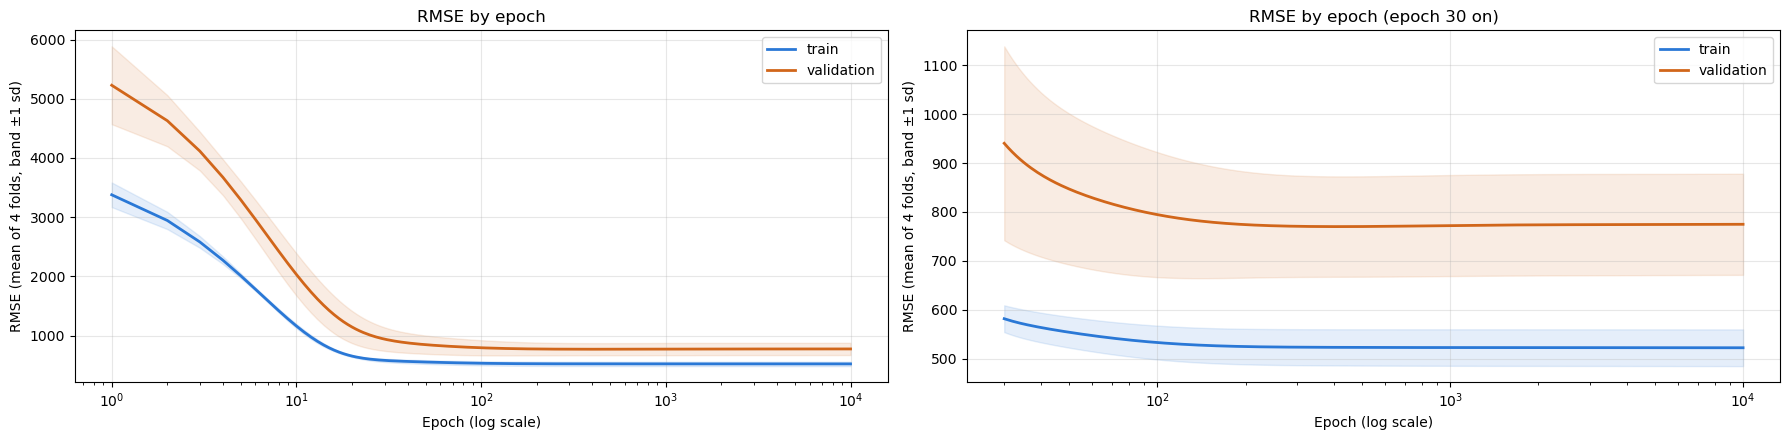

In [25]:
EPOCHS = 10_000

curve = PIPELINES.loss_curve(build(FEATURE_CHOICE, SELECTED_MODEL, degree=DEGREE, scale=True), X=X, y=y, folds=FOLDS, epochs=EPOCHS)

by_epoch = curve.groupby(level="epoch").mean()
print(f"lowest validation rmse: {by_epoch['validation rmse'].min():.3f} at epoch {by_epoch['validation rmse'].idxmin()}")

display(by_epoch.loc[[1, 10, 30, 100, 300, 1000, 3000, 10_000]].round(3))
PLOTTING.loss_curve(curve=curve, zoom_from=30, log_x=True);

## Save the Model

The fitted pipeline takes the 11 attributes as they are stored and builds its own feature columns, so it predicts on new rows with no preprocessing outside it.

In [26]:
MODEL_OUTPUT_DIR.mkdir(exist_ok=True)

model_path = MODEL_OUTPUT_DIR / "polynomial_regression.joblib"
joblib.dump(final_model, model_path)

reloaded = joblib.load(model_path)
print(f"saved: {model_path.name}")
print(f"reloaded predictions identical: {np.array_equal(reloaded.predict(X), final_model.predict(X))}")

saved: polynomial_regression.joblib
reloaded predictions identical: True


## Results

- **The selected model is degree 2 with Lasso at `alpha=0.001` and `eta0=0.001`,** at an rmse of 767.440 over the 4 folds. It is the smaller of the two tied penalties, and it is selected because the question asks for the best regularized setting: plain SGD scores 766.258 and closed form 772.910.
- **It beats Q2D's linear model, by a margin that 4 folds can only call a candidate.** Against `Linear, Lasso SGD` (792.708) its rmse is lower by 25.268 with an SE of 11.763 (Δ / SE -2.148, p 0.060), and r2 rises from 0.461 to 0.500. The gain comes from the polynomial terms: every degree 2 row is a **candidate** against that model, with or without a penalty.
- **Fit on all 584 training rows, it stops after 1,753 epochs** with a training rmse of 569.145. None of its 20 coefficients is exactly 0. Year is the largest (922.8), and two of the next three are polynomial terms: Temp squared (-745.6) and the square of FeelsLike's flat top (580.3).
- **The loss curve shows only slight overfitting with more training.** Validation rmse falls from 5227.541 at epoch 1 to 794.430 at epoch 100, is lowest at epoch 416 (769.948), then drifts up to 774.678 by epoch 10,000 while training rmse edges down (523.180 at epoch 300, 521.987 at the end).

**Carry forward**

- **`polynomial_regression.joblib`,** the fitted pipeline, which reloads with identical predictions. Its cross validated rmse of 767.440 is the estimate for days it has not seen.

# Overfitting and Underfitting

Four views of overfitting and underfitting are already above: by degree with closed form (Degree), by the columns that are expanded (What Is Expanded), by where SGD stops (Stopping Tolerance) and by penalty strength (Regularization). This section adds SGD at the other degrees and the last view, by epoch.

## Other Degrees with SGD

The selected setting on the same feature columns at degrees 1, 3 and 4, each stopped by its own rule. The degree was chosen with closed form, so these rows show how the degree behaves under SGD. They are not up for selection.

In [27]:
OTHER_DEGREES = {f"Degree {degree}, selected setting": degree for degree in [1, 3, 4]}
BY_DEGREE = {SELECTED_NAME: DEGREE, **OTHER_DEGREES}

for name, degree in OTHER_DEGREES.items():
	score(name, build(FEATURE_CHOICE, SELECTED_MODEL, degree=degree, scale=True))

# epochs each degree runs before it stops
display(pd.concat([epochs_run({name: SELECTED_MODEL}, degree=degree) for name, degree in BY_DEGREE.items()]))
display(fold_range(list(BY_DEGREE)))
display(table(list(BY_DEGREE), baseline=SELECTED_NAME))

,fold 1,fold 2,fold 3,fold 4,all rows,fits at the limit
"Lasso, alpha=0.001",2463,2826,1931,1685,1753,0
"Degree 1, selected setting",13861,11023,11200,9331,7311,0
"Degree 3, selected setting",1319,1640,1534,1246,974,0
"Degree 4, selected setting",939,1120,729,507,553,0


,rmse mean,train rmse mean,lowest fold,median fold,highest fold,folds above Dummy
"Lasso, alpha=0.001",767.440,522.146,652.994,764.555,887.655,0
"Degree 1, selected setting",794.294,570.322,706.425,789.843,891.067,0
"Degree 3, selected setting",759.076,510.723,626.577,772.008,865.709,0
"Degree 4, selected setting",769.460,499.847,604.518,810.776,851.770,0


,rmse mean,rmse sd,train rmse mean,mae mean,mae sd,r2 mean,r2 sd,"Δrmse vs Lasso, alpha=0.001",Δrmse SE,Δ / SE,p,verdict,folds
intervention,,,,,,,,,,,,,
"Degree 3, selected setting",759.076,101.278,510.723,591.945,77.500,0.515,0.108,-8.364,11.073,-0.755,0.252,within noise,4
"Lasso, alpha=0.001",767.440,97.661,522.146,600.826,91.041,0.500,0.129,0.000,NaN,NaN,NaN,baseline,4
"Degree 4, selected setting",769.460,116.127,499.847,606.212,89.722,0.507,0.095,2.020,31.314,0.065,0.524,within noise,4
"Degree 1, selected setting",794.294,77.374,570.322,604.464,71.550,0.458,0.161,26.855,12.173,2.206,0.943,worse,4


## Loss by Epoch at Degrees 1 to 4

The same one epoch at a time loop as for the selected model, with the degree as the only change. Degree 2 is the curve from the Selected Model section.

,lowest validation rmse,at epoch,validation rmse at epoch 10000,train rmse at epoch 10000
Degree 1,790.701,10000,790.701,570.834
Degree 2 (selected),769.948,416,774.678,521.987
Degree 3,760.502,2485,760.799,505.481
Degree 4,760.072,6927,760.388,483.774


Degree 1                 Degree 2 (selected)                  \
      train rmse validation rmse          train rmse validation rmse   
epoch                                                                  
30       648.356        1066.470             581.424         940.439   
100      614.407         928.844             532.666         794.430   
300      588.703         851.275             523.180         770.568   
1000     571.809         798.148             522.404         772.077   
3000     570.837         790.776             522.236         773.945   
10000    570.834         790.701             521.987         774.678   

        Degree 3                   Degree 4                  
      train rmse validation rmse train rmse validation rmse  
epoch                                                        
30       559.092         927.204    545.765         925.548  
100      517.433         771.460    505.605         782.720  
300      510.517         761.870    497.708         770.569  
1000     508.046         761.065    492.250         766.600  
3000     506.741         760.512    487.538         762.126  
10000    505.481         760.799    483.774         760.388

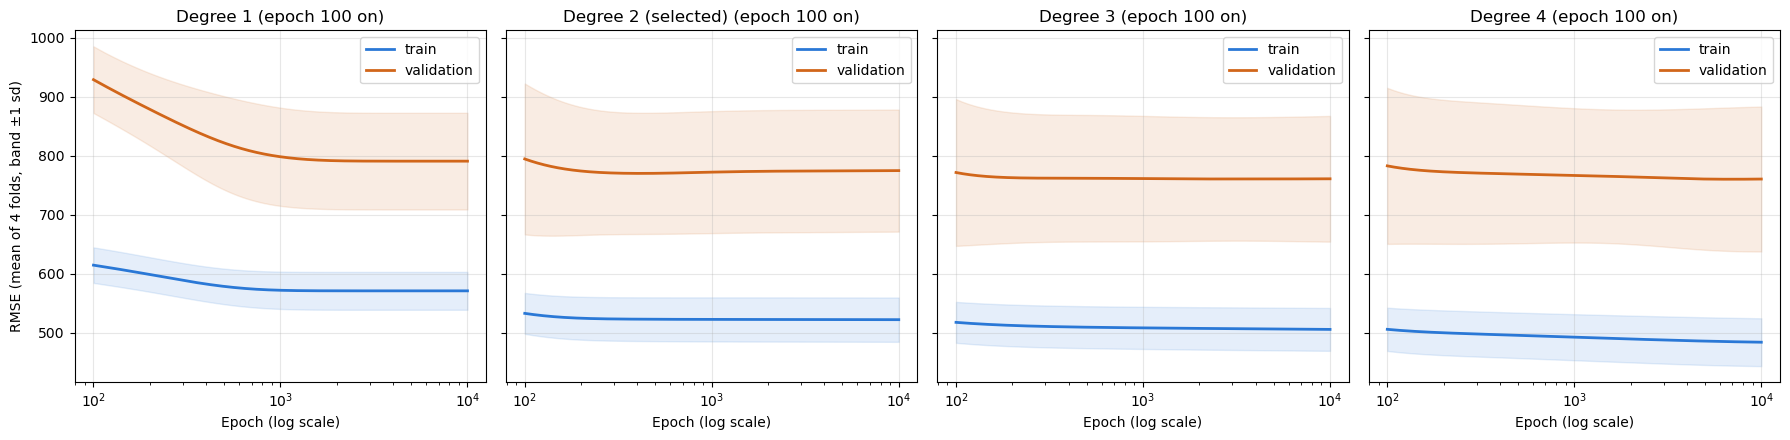

In [28]:
curves = {
	f"Degree {degree}" + (" (selected)" if degree == DEGREE else ""):
		curve if degree == DEGREE
		else PIPELINES.loss_curve(build(FEATURE_CHOICE, SELECTED_MODEL, degree=degree, scale=True), X=X, y=y, folds=FOLDS, epochs=EPOCHS)
	for degree in [1, 2, 3, 4]
}

means = {name: one.groupby(level="epoch").mean() for name, one in curves.items()}

display(
	pd.DataFrame({
		name: {
			"lowest validation rmse": mean["validation rmse"].min(),
			"at epoch": mean["validation rmse"].idxmin(),
			f"validation rmse at epoch {EPOCHS}": mean["validation rmse"].iloc[-1],
			f"train rmse at epoch {EPOCHS}": mean["train rmse"].iloc[-1],
		}
		for name, mean in means.items()
	}).T.round(3).astype({"at epoch": int})
)
display(pd.concat(means, axis=1).loc[[30, 100, 300, 1000, 3000, 10_000]].round(3))
PLOTTING.loss_curve(curve=curves, zoom_from=100, log_x=True);

## Results

- **The selected model does not underfit, and overfits only slightly.** Its loss curve ends just above its lowest validation rmse (774.678 against 769.948). Across the folds its training and validation rmse are 522.146 and 767.440, a gap the linear model has too (570.322 and 794.294 at degree 1).
- **Degree 1 underfits.** With the selected setting it is worse than degree 2 by 26.855 against an SE of 12.173, and its training rmse is higher as well. By epoch its two lines are flat from epoch 3,000 on: 570.837 and 790.776 there, 570.834 and 790.701 at the end.
- **Degrees 3 and 4 fit the training rows more closely, with no gain that holds.** Stopped by their rule they are within noise of the selected model (759.076 and 769.460), as they were with closed form. By epoch their training rmse falls for all 10,000 epochs (to 505.481 and 483.774), while their validation rmse levels off: 760.512 and 762.126 at epoch 3,000, 760.799 and 760.388 at the end. It does not rise, so more training does not hurt them here.
- **The clear cases are in the other views.** Expanding all 10 columns overfits: training rmse 458.010 against a validation rmse of 793.152, and at degree 3 it fails on every fold. A strong penalty or an early stop underfits, with both scores rising together: 562.893 and 917.411 for Ridge at `alpha=0.1`, 593.278 and 981.985 at `tol=1000`.

**Carry forward**

- **Degree 2 stays.** Degrees 3 and 4 are within noise of it with closed form and with SGD, and ties go to the lower degree.